# From earthquake deformation to an initial tsunami surface

Suppose your tsunami model asks for an **initial water-surface elevation**. A familiar starting point is to copy the earthquake’s vertical ground displacement onto the ocean surface. This notebook uses a full-margin Cascadia rupture to show when that approximation works and why the other two maps can differ from it. All elevations and displacements are in metres, positive upward.

Install `deform2tsunami` in the notebook’s Python environment. Put one rupture’s **surface.h5** beside the notebook or set its path below. The example writes 30 arcsecond longitude–latitude rasters from northern California to Vancouver Island. For a different source, change the bounds or use `None` for the full mesh extent.

In [1]:
import os
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import numpy as np
import rasterio
from rasterio.plot import plotting_extent
from deform2tsunami import export_raster

source = Path(os.environ.get("DEFORM2TSUNAMI_EXAMPLE", "surface.h5")).expanduser()
bounds = (-130.5, 39.6, -121.0, 51.0)  # west, south, east, north in degrees
arcsec = 30
out = Path("rasters")
out.mkdir(exist_ok=True)
with h5py.File(source, "r") as h:
    print("Input:", h.attrs.get("scenario", source.name))
    has_eta0 = "tsunami/eta0" in h
    print("Archived initial water surface present:", has_eta0)

Input: DOGAMI-Aexp-T100-S-Sym-L-U
Archived initial water surface present: False


## 1. Start with vertical displacement

Pick a point on the seabed and follow that piece of ground during the earthquake. The raster `vertical.tif` gives the vertical component of its motion, $u_z$. If the patch rose 1 m, the raster reads +1 m. Using that value as the initial water elevation assumes the water surface directly above it also rose 1 m.

That is a useful first approximation for rapid, broad uplift in water shallow compared with the uplift wavelength, especially where the bed is nearly flat. Two questions arise along the Cascadia margin. How much does the bed elevation change at a **fixed map location** when a slope slides sideways? And how much of that change reaches the **water surface**?

## 2. Account for horizontal motion across a slope

A tsunami grid cell stays at a fixed longitude and latitude while the solid Earth moves beneath it. Imagine a seabed that rises 1 m for every 10 m east. If the bed slides 10 m **west** with zero vertical motion, the point now under your grid cell came from 10 m farther east, where the bed was 1 m higher. The vertical-displacement raster reads **0 m**, yet the bed at the cell has risen **1 m**. Sliding along a depth contour contributes zero through this mechanism.

Let $b(x,y)$ be the original bed elevation, positive upward, and $(u_x,u_y,u_z)$ the displacement in the same projected axes. To first order, the change in bed elevation at a fixed location is

$$\Delta b = u_z - u_x\,\frac{\partial b}{\partial x} - u_y\,\frac{\partial b}{\partial y}.$$

The exporter uses the slope of each original mesh triangle to compute `bed-change.tif`. On a flat bed, $\Delta b=u_z$. On a steep slope, horizontal motion can reinforce or offset vertical uplift. This raster describes the **permanent terrain change**: adding it to the original elevation gives the post-earthquake terrain to first order. [Tanioka & Satake (1996)](https://doi.org/10.1029/96GL00736)

## 3. Transfer the bed change through the water column

Now consider two uplift patches with the same peak $\Delta b$. Over a broad patch the sea surface can rise almost as much as the bed. Over a narrow ridge in deep water, water also moves sideways. The surface response spreads over a wider area and its crest is lower. The **Kajiura filter** represents this spatial smoothing during rapid generation.

For a single bed-deformation wavelength $\lambda$ under water of constant depth $h$, the fraction of its amplitude that reaches the surface is $1/\cosh(2\pi h/\lambda)$. In 3 km of water, a 60 km wavelength retains about **95%** of its amplitude, while a 6 km wavelength retains about **9%**. For variable depth, the tool approximates this response using the depth above each source location. [Kajiura (1963)](https://doi.org/10.15083/0000033711) · [Abbate et al. (2024)](https://doi.org/10.5194/nhess-24-2773-2024)

**For a tsunami model initialized from static earthquake deformation, the most complete initial water elevation in this workflow includes both effects in sequence:** first compute the slope-corrected offshore $\Delta b$, then apply Kajiura to obtain $\eta_0=\mathcal K_h[\Delta b]$. The two corrections are already included in $\eta_0$.

| If your model asks for… | Use… |
| --- | --- |
| Initial water-surface **elevation** relative to still water | `eta0-recomputed.tif` or `eta0.tif`. The first filters the original deformation on a 500 m working grid. The second interpolates the filtered values already stored at mesh vertices, when available. |
| Permanent **change in bed elevation** | `bed-change.tif`, following the model’s elevation/depth sign convention. |

These are two different physical inputs. If the solver itself generates the wave from a moving bed, applying the same earthquake again as an initial water elevation would double-count generation. The static workflow assumes rapid deformation and supplies an elevation field; rupture timing and initial water velocities require additional information.

## Write the GeoTIFFs

The cell below exports the two ground fields and recomputes the water surface from the slope-corrected bed change. If the HDF5 also has an archived water surface, the cell exports it for comparison. Rerunning this cell replaces the named example outputs in `rasters/`.

In [2]:
fields = ["vertical", "bed-change"]
if has_eta0:
    fields.append("eta0")
fields.append("eta0-recomputed")

paths = {}
for field in fields:
    paths[field] = export_raster(source, out / f"{field}.tif", field,
                                 bounds=bounds, arcsec=arcsec, overwrite=True)

for field, path in paths.items():
    with rasterio.open(path) as ds:
        grid = ds.read(1, masked=True)
        print(f"{path}  |  {ds.crs}  |  {ds.width} × {ds.height}  |  "
              f"{grid.min():.2f} to {grid.max():.2f} m")

rasters/vertical.tif  |  EPSG:4326  |  1140 × 1368  |  -3.02 to 12.83 m
rasters/bed-change.tif  |  EPSG:4326  |  1140 × 1368  |  -3.24 to 14.70 m
rasters/eta0-recomputed.tif  |  EPSG:4326  |  1140 × 1368  |  -2.99 to 10.90 m


## Read the Cascadia maps from left to right

First compare **Vertical displacement** with **Bed elevation change** along the offshore uplift ridge. The extra short-scale variation in the second panel comes from horizontal displacement across the sloping bed. Next compare **Bed elevation change** with **Recomputed water surface**. The broad uplift belt is still visible, but the sharp ridge is smoother. In the example run, the regional maximum goes from **12.83 m** in vertical displacement to **14.70 m** in effective bed change and **10.90 m** in initial water elevation. These are map-wide peaks and can occur at different pixels.

All panels use the same colour scale. The thin gray outline marks the wet footprint of the recomputed water surface. The ground fields also extend onto land, where permanent subsidence or uplift can matter for inundation.

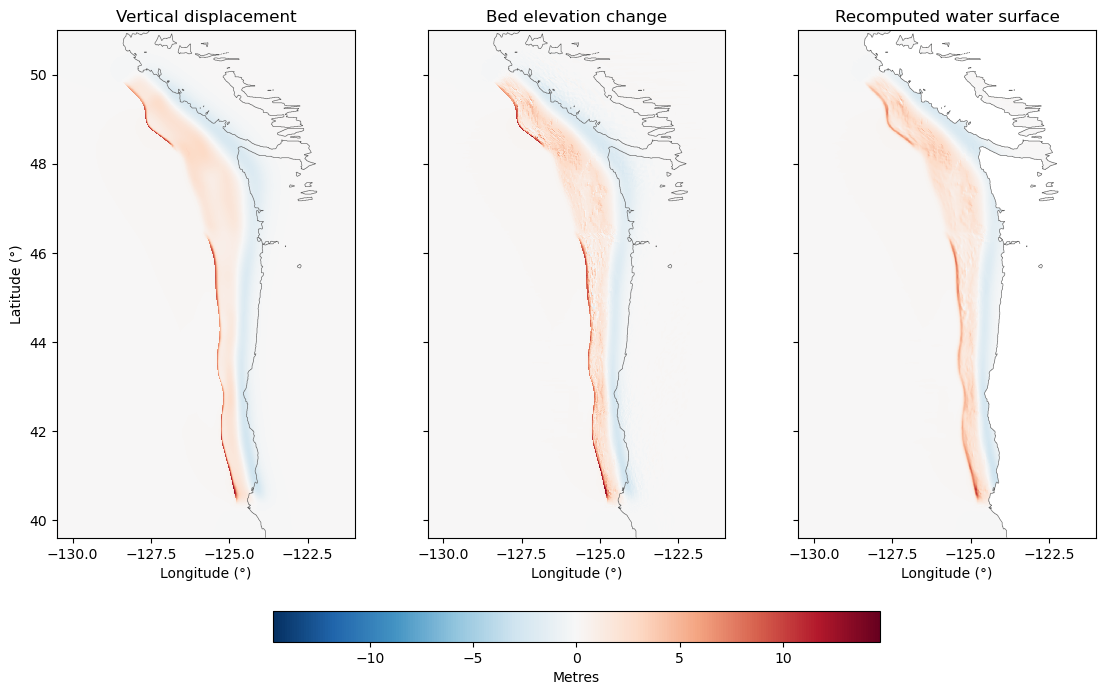

In [3]:
# Use the model's wet footprint as a common geographic reference on every panel.
with rasterio.open(paths["eta0-recomputed"]) as water:
    wet = water.read_masks(1) > 0
    lon = water.bounds.left + (np.arange(water.width) + 0.5) * water.res[0]
    lat = water.bounds.top - (np.arange(water.height) + 0.5) * water.res[1]

fig, axes = plt.subplots(1, len(paths), figsize=(3.8 * len(paths), 6.8),
                         sharex=True, sharey=True, constrained_layout=True)
titles = {"vertical": "Vertical displacement", "bed-change": "Bed elevation change",
          "eta0": "Archived water surface", "eta0-recomputed": "Recomputed water surface"}
limit = 0
images = []
for ax, (field, path) in zip(axes, paths.items()):
    with rasterio.open(path) as ds:
        grid = ds.read(1, masked=True)
        images.append(ax.imshow(grid, extent=plotting_extent(ds), cmap="RdBu_r",
                                interpolation="nearest", origin="upper"))
        if grid.count():
            limit = max(limit, float(np.abs(grid).max()))
        latitude = (ds.bounds.bottom + ds.bounds.top) / 2
    if wet.any() and not wet.all():
        ax.contour(lon, lat, wet, levels=[0.5], colors="0.38", linewidths=0.45)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=4))
    ax.set_aspect(1 / np.cos(np.deg2rad(latitude)))
    ax.set(title=titles[field], xlabel="Longitude (°)")
for image in images:
    image.set_clim(-max(limit, 0.01), max(limit, 0.01))
axes[0].set_ylabel("Latitude (°)")
fig.colorbar(images[0], ax=list(axes), orientation="horizontal", shrink=.55, label="Metres")
plt.show()

## Where does Kajiura filtering change the initial water elevation?

Subtract the **slope-corrected bed change** from the **recomputed initial water elevation** at each wet pixel: $\delta\eta = \eta_0 - \Delta b$. Both fields already include horizontal ground motion over the slope, so this comparison isolates the effect of transferring the bed deformation through the water column.

**Blue** means the filtered water surface starts lower than it would if we copied the bed change directly. **Red** means it starts higher. Look for blue along a narrow uplift crest and red on its flanks, where the filtered crest has spread sideways. Near-white means the two initial elevations agree closely, even where both are large. Gray marks land or missing data.

The color scale saturates at ±2 m when the differences exceed that range so smaller offshore changes remain visible. The values printed beneath the map use the full range.

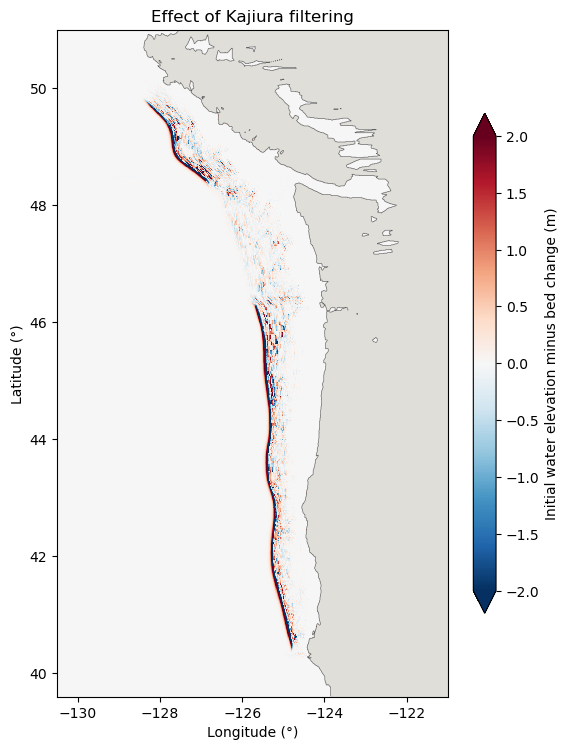

Offshore difference: -8.48 to +6.40 m


In [4]:
with rasterio.open(paths["bed-change"]) as bed, rasterio.open(paths["eta0-recomputed"]) as water:
    if (bed.crs, bed.transform, bed.shape) != (water.crs, water.transform, water.shape):
        raise ValueError("Bed and water rasters must share a grid for pixel-wise subtraction.")
    difference = water.read(1, masked=True) - bed.read(1, masked=True)
    extent = plotting_extent(water)

if not difference.count():
    raise ValueError("The selected bounds contain no supported offshore pixels.")
lo, hi = float(difference.min()), float(difference.max())
limit = min(2.0, max(abs(lo), abs(hi), 0.01))
extend = {(False, False): "neither", (True, False): "min",
          (False, True): "max", (True, True): "both"}[lo < -limit, hi > limit]

fig, ax = plt.subplots(figsize=(6.3, 7.4), constrained_layout=True)
ax.set_facecolor("#dfded9")
im = ax.imshow(difference, extent=extent, origin="upper", interpolation="nearest",
               cmap="RdBu_r", vmin=-limit, vmax=limit)
if wet.any() and not wet.all():
    ax.contour(lon, lat, wet, levels=[0.5], colors="0.38", linewidths=0.45)
ax.set_aspect(1 / np.cos(np.deg2rad((extent[2] + extent[3]) / 2)))
ax.set(title="Effect of Kajiura filtering", xlabel="Longitude (°)", ylabel="Latitude (°)")
fig.colorbar(im, ax=ax, shrink=.75, extend=extend, label="Initial water elevation minus bed change (m)")
plot_dir = out / "plots"
plot_dir.mkdir(exist_ok=True)
fig.savefig(plot_dir / "kajiura_minus_bed_change.png", dpi=160, bbox_inches="tight")
plt.show()
print(f"Offshore difference: {lo:+.2f} to {hi:+.2f} m")